In [60]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,confusion_matrix, classification_report
from sklearn.preprocessing import StandardScaler, LabelEncoder
from torch.utils.data import TensorDataset, DataLoader
import pandas as pd
import matplotlib.pyplot as plt

In [27]:
df = pd.read_csv("customers.csv")
df

,ID,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation
0,462809,Male,No,22,No,Healthcare,1.0,Low,4.0,Cat_4,D
1,462643,Female,Yes,38,Yes,Engineer,NaN,Average,3.0,Cat_4,A
2,466315,Female,Yes,67,Yes,Engineer,1.0,Low,1.0,Cat_6,B
3,461735,Male,Yes,67,Yes,Lawyer,0.0,High,2.0,Cat_6,B
4,462669,Female,Yes,40,Yes,Entertainment,NaN,High,6.0,Cat_6,A
...,...,...,...,...,...,...,...,...,...,...,...
10690,467954,Male,No,29,No,Healthcare,9.0,Low,4.0,Cat_6,B
10691,467958,Female,No,35,Yes,Doctor,1.0,Low,1.0,Cat_6,A
10692,467960,Female,No,53,Yes,Entertainment,NaN,Low,2.0,Cat_6,C
10693,467961,Male,Yes,47,Yes,Executive,1.0,High,5.0,Cat_4,C


In [28]:
df.drop(columns = ['ID'], inplace = True)
df

,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation
0,Male,No,22,No,Healthcare,1.0,Low,4.0,Cat_4,D
1,Female,Yes,38,Yes,Engineer,NaN,Average,3.0,Cat_4,A
2,Female,Yes,67,Yes,Engineer,1.0,Low,1.0,Cat_6,B
3,Male,Yes,67,Yes,Lawyer,0.0,High,2.0,Cat_6,B
4,Female,Yes,40,Yes,Entertainment,NaN,High,6.0,Cat_6,A
...,...,...,...,...,...,...,...,...,...,...
10690,Male,No,29,No,Healthcare,9.0,Low,4.0,Cat_6,B
10691,Female,No,35,Yes,Doctor,1.0,Low,1.0,Cat_6,A
10692,Female,No,53,Yes,Entertainment,NaN,Low,2.0,Cat_6,C
10693,Male,Yes,47,Yes,Executive,1.0,High,5.0,Cat_4,C


In [29]:
df.fillna({'Work_Experience' : 0, 'Family_Size': df['Family_Size'].median()}, inplace = True)

,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation
0,Male,No,22,No,Healthcare,1.0,Low,4.0,Cat_4,D
1,Female,Yes,38,Yes,Engineer,0.0,Average,3.0,Cat_4,A
2,Female,Yes,67,Yes,Engineer,1.0,Low,1.0,Cat_6,B
3,Male,Yes,67,Yes,Lawyer,0.0,High,2.0,Cat_6,B
4,Female,Yes,40,Yes,Entertainment,0.0,High,6.0,Cat_6,A
...,...,...,...,...,...,...,...,...,...,...
10690,Male,No,29,No,Healthcare,9.0,Low,4.0,Cat_6,B
10691,Female,No,35,Yes,Doctor,1.0,Low,1.0,Cat_6,A
10692,Female,No,53,Yes,Entertainment,0.0,Low,2.0,Cat_6,C
10693,Male,Yes,47,Yes,Executive,1.0,High,5.0,Cat_4,C


In [30]:
df.columns

Index(['Gender', 'Ever_Married', 'Age', 'Graduated', 'Profession',
       'Work_Experience', 'Spending_Score', 'Family_Size', 'Var_1',
       'Segmentation'],
      dtype='str')

In [31]:
cat_cols = ['Gender', 'Ever_Married', 'Graduated', 'Profession', 'Spending_Score', 'Var_1','Segmentation']
for  col in cat_cols:
    df[col] = LabelEncoder().fit_transform(df[col])

df

,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation
0,1,0,22,0,5,1.0,2,4.0,3,3
1,0,1,38,1,2,0.0,0,3.0,3,0
2,0,1,67,1,2,1.0,2,1.0,5,1
3,1,1,67,1,7,0.0,1,2.0,5,1
4,0,1,40,1,3,0.0,1,6.0,5,0
...,...,...,...,...,...,...,...,...,...,...
10690,1,0,29,0,5,9.0,2,4.0,5,1
10691,0,0,35,1,1,1.0,2,1.0,5,0
10692,0,0,53,1,3,0.0,2,2.0,5,2
10693,1,1,47,1,4,1.0,1,5.0,3,2


In [37]:
x = df.drop(columns = ['Segmentation'])
y = df['Segmentation'].values
xt,xst,yt,yts = train_test_split(x,y,test_size = 0.2, random_state = 42)

In [39]:
scaler1 = StandardScaler()
scaler2 = StandardScaler()
xt = scaler1.fit_transform(xt)
xst = scaler2.fit_transform(xst)

In [40]:
xt = torch.FloatTensor(xt)
xst = torch.FloatTensor(xst)
yt = torch.FloatTensor(yt)
yst = torch.FloatTensor(yts)

In [48]:
train = TensorDataset(xt, yt)
test = TensorDataset(xst,yst)
trl = DataLoader(train,batch_size=16,shuffle = True)
tsl = DataLoader(test,batch_size = 16)

In [49]:
class classification_model(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.l1 = nn.Linear(input_size, 32)
        self.l2 = nn.Linear(32, 16)
        self.l3 = nn.Linear(16, 8)
        self.l4 = nn.Linear(8, 4)

    def forward(self, x):
        x = F.relu(self.l1(x))
        x = F.relu(self.l2(x))
        x = F.relu(self.l3(x))
        x = self.l4(x)
        return x




         

In [50]:
model = classification_model(xt.shape[1])
criterion = nn.CrossEntropyLoss()
op = optim.Adam(model.parameters(), lr = 0.001)

In [54]:
epochs = 100
for i in range(epochs):
    for a,b in trl:
        pred = model(a)
        loss = criterion(pred,b.long())
        loss.backward()
        op.step()
        if i % 10 == 0:
            print(f"Loss {i + 1} / e Loss: {loss.item()}")

Loss 1 / e Loss: 1.4365246295928955
Loss 1 / e Loss: 1.378433108329773
Loss 1 / e Loss: 1.2773703336715698
Loss 1 / e Loss: 1.469828724861145
Loss 1 / e Loss: 1.4504667520523071
Loss 1 / e Loss: 1.4265865087509155
Loss 1 / e Loss: 1.4032783508300781
Loss 1 / e Loss: 1.5734115839004517
Loss 1 / e Loss: 1.3482497930526733
Loss 1 / e Loss: 1.3512920141220093
Loss 1 / e Loss: 1.3571140766143799
Loss 1 / e Loss: 1.398856282234192
Loss 1 / e Loss: 1.3870174884796143
Loss 1 / e Loss: 1.3994643688201904
Loss 1 / e Loss: 1.338114857673645
Loss 1 / e Loss: 1.505053162574768
Loss 1 / e Loss: 1.4233001470565796
Loss 1 / e Loss: 1.4168022871017456
Loss 1 / e Loss: 1.4401049613952637
Loss 1 / e Loss: 1.3937653303146362
Loss 1 / e Loss: 1.471795916557312
Loss 1 / e Loss: 1.2844160795211792
Loss 1 / e Loss: 1.3363269567489624
Loss 1 / e Loss: 1.4400125741958618
Loss 1 / e Loss: 1.4299472570419312
Loss 1 / e Loss: 1.2878285646438599
Loss 1 / e Loss: 1.35751473903656
Loss 1 / e Loss: 1.3653688430786133


In [57]:
act = []
pre = []
with torch.no_grad():
    for a,b in tsl:
        pred = model(a)
        _,output = torch.max(pred,1)
        pre.extend(output.numpy())
        act.extend(b.numpy())




In [65]:
accuracy = accuracy_score(act,pre)
conf_matrix = confusion_matrix(act,pre)
class_report = classification_report(act,pre,target_names = ['A','B','C','D'])
print("Accuracy = ",accuracy)
print("Confusion Matrix = \n",conf_matrix)
print("Classification Report = \n",class_report)

Accuracy =  0.2772323515661524
Confusion Matrix = 
 [[  0   0   0 584]
 [  0   0   0 490]
 [  0   0   0 472]
 [  0   0   0 593]]
Classification Report = 
               precision    recall  f1-score   support

           A       0.00      0.00      0.00       584
           B       0.00      0.00      0.00       490
           C       0.00      0.00      0.00       472
           D       0.28      1.00      0.43       593

    accuracy                           0.28      2139
   macro avg       0.07      0.25      0.11      2139
weighted avg       0.08      0.28      0.12      2139



c:\Users\ahama\OneDrive\Documents\New folder\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\ahama\OneDrive\Documents\New folder\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\ahama\OneDrive\Documents\New folder\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifi

Text(0.5, 1.0, 'Confusion Matrix')

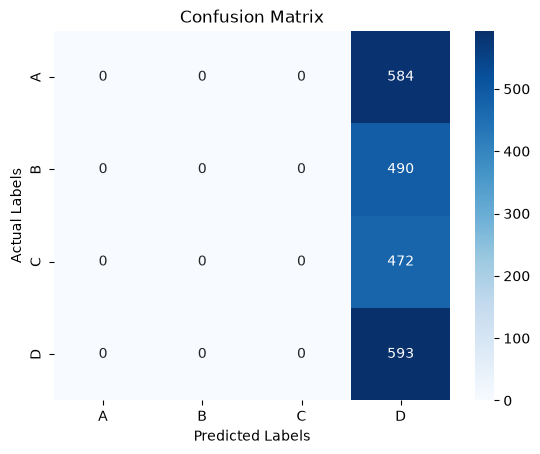

In [68]:
sns.heatmap(conf_matrix,annot = True,fmt = 'd', cmap = 'Blues', xticklabels = ['A','B','C','D'], yticklabels = ['A','B','C','D'])
plt.xlabel("Predicted Labels")
plt.ylabel("Actual Labels")
plt.title("Confusion Matrix")
